# EcoNet: CNN construida y entrenada desde cero para clasificar residuos

**Proyecto 4 – Detección de residuos y clasificación de basura** · Sistemas de Inteligencia Artificial

En este notebook se **diseña y entrena desde cero** una red neuronal convolucional (CNN): no se usan pesos pre-entrenados ni *fine-tuning*. Todos los pesos parten de valores aleatorios y se aprenden únicamente con nuestro dataset.

La red clasifica cada residuo en 6 clases, y a partir de la clase se determina si es orgánico o inorgánico y en qué caneca va (Resolución 2184 de 2019):

| Clase | Tipo | Caneca |
|---|---|---|
| Plástico, Papel, Cartón, Vidrio, Metal | Inorgánico | Blanca |
| Orgánico | Orgánico | Verde |

### ¿Cómo funciona una CNN?
- **Convolución:** filtros de 3×3 que se deslizan sobre la imagen y detectan patrones locales: bordes y colores en las primeras capas; texturas y formas (la ondulación del cartón, el brillo del metal, la transparencia del vidrio) en las capas profundas.
- **BatchNorm + ReLU:** normalizan y agregan no linealidad para que la red aprenda patrones complejos y entrene de forma estable.
- **MaxPooling:** reduce la resolución a la mitad, lo que da invariancia a pequeños desplazamientos y amplía el campo receptivo.
- **Global Average Pooling + capa lineal:** resume cada mapa de características en un número y decide la clase.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt, seaborn as sns
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from config import DATA_PROC, CLASES, INFO_CLASES, CNN_PESOS, OUTPUTS, TAM_IMAGEN
from src.cnn import EcoNet, tf_entrenamiento, tf_evaluacion

torch.manual_seed(42); np.random.seed(42)
OUTPUTS.mkdir(exist_ok=True); CNN_PESOS.parent.mkdir(exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

Dispositivo: cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Dataset
Dataset público *Garbage Classification (12 clases)*. `prepare_data.py` agrupa las clases en 6 (se unen los 3 tipos de vidrio y *biological* pasa a ser *orgánico*) y divide los datos en 70 % entrenamiento, 15 % validación y 15 % prueba. Las imágenes se cargan en memoria una sola vez para acelerar el entrenamiento.

In [2]:
from src.cnn import Residuos   # dataset definido en src/cnn.py (necesario para cargar en paralelo)
t0 = time.time()
ds = {'train': Residuos(DATA_PROC, 'train', tf_entrenamiento), 'val': Residuos(DATA_PROC, 'val', tf_evaluacion), 'test': Residuos(DATA_PROC, 'test', tf_evaluacion)}
for k, d in ds.items():
    conteo = np.bincount([y for _, y in d.items], minlength=len(CLASES))
    print(f'{k:5s} {len(d):5d} imágenes', dict(zip(CLASES, conteo.tolist())))
print(f'Cargado en {time.time()-t0:.1f} s')

train  4601 imágenes {'carton': 623, 'metal': 538, 'organico': 689, 'papel': 735, 'plastico': 605, 'vidrio': 1411}
val     986 imágenes {'carton': 134, 'metal': 115, 'organico': 148, 'papel': 157, 'plastico': 130, 'vidrio': 302}
test    989 imágenes {'carton': 134, 'metal': 116, 'organico': 148, 'papel': 158, 'plastico': 130, 'vidrio': 303}
Cargado en 13.1 s


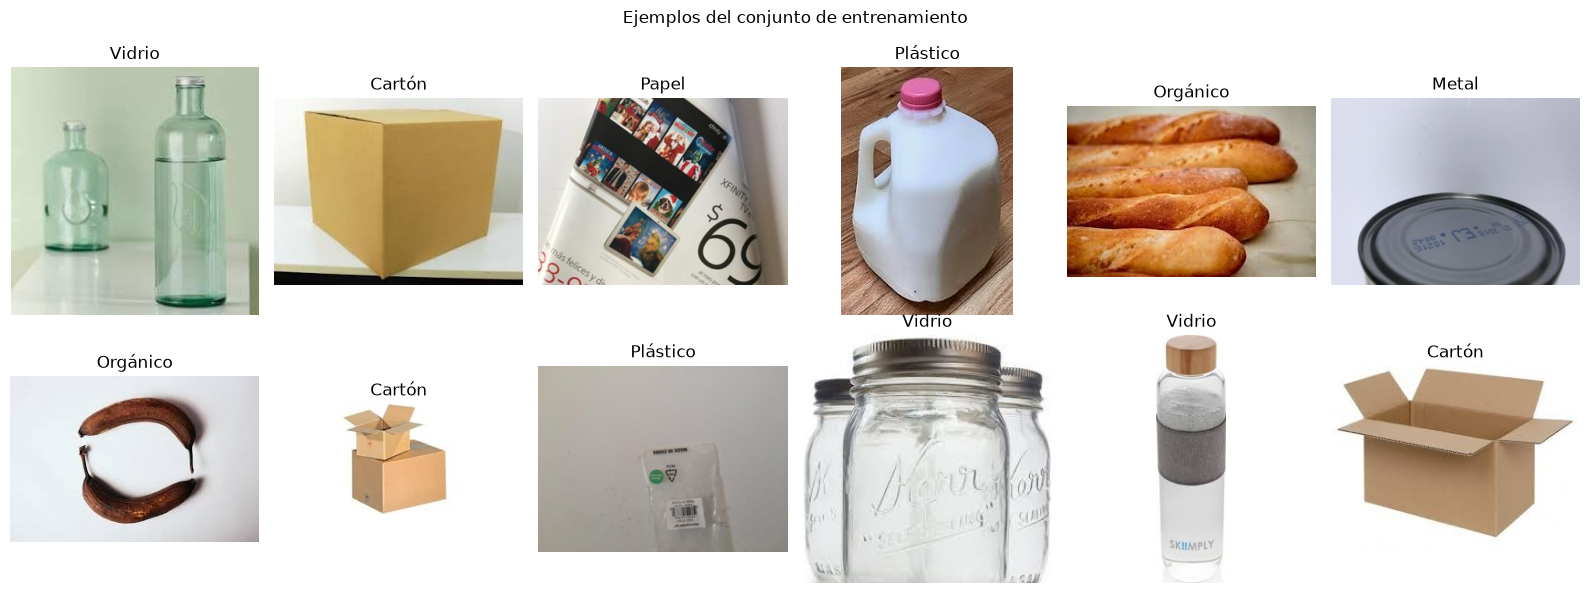

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
rng = np.random.default_rng(0)
for ax, i in zip(axes.flat, rng.choice(len(ds['train']), 12, replace=False)):
    ax.imshow(ds['train'].imgs[i]); ax.set_title(INFO_CLASES[CLASES[ds['train'].items[i][1]]]['nombre']); ax.axis('off')
plt.suptitle('Ejemplos del conjunto de entrenamiento'); plt.tight_layout()
plt.savefig(OUTPUTS / 'ejemplos_dataset.png', dpi=120); plt.show()

### Aumento de datos (*data augmentation*)
Como la red parte de cero y el dataset es pequeño, en cada época se generan variaciones aleatorias de cada imagen (recortes, giros, rotaciones y cambios de color). Así la red aprende la forma y la textura del material y no memoriza imágenes concretas.

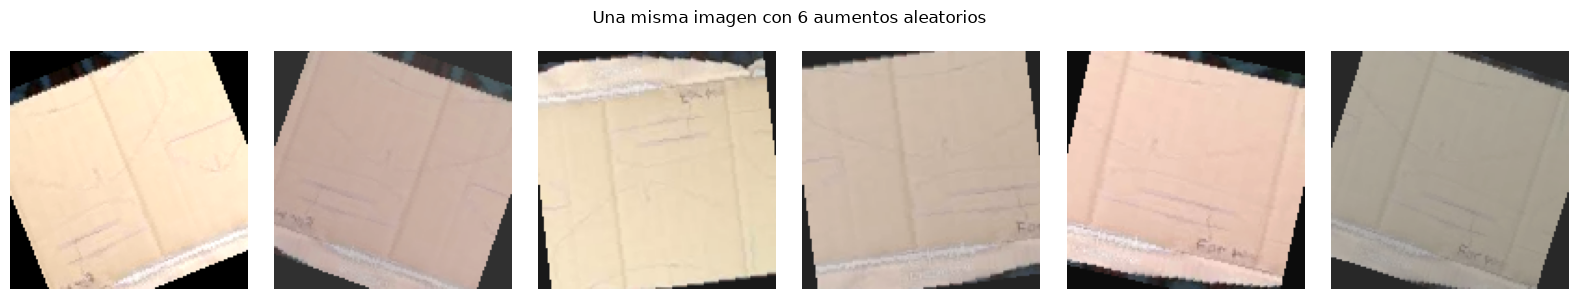

In [4]:
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax in axes:
    x, y = ds['train'][5]
    ax.imshow((x.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1)); ax.axis('off')
plt.suptitle('Una misma imagen con 6 aumentos aleatorios'); plt.tight_layout()
plt.savefig(OUTPUTS / 'aumento_datos.png', dpi=120); plt.show()

## 2. Arquitectura de EcoNet (pesos aleatorios)

In [5]:
modelo = EcoNet(len(CLASES)).to(device)
print(modelo)
n = sum(p.numel() for p in modelo.parameters())
print(f'\nParámetros entrenables: {n:,} (todos inicializados aleatoriamente)')
x = torch.zeros(1, 3, TAM_IMAGEN, TAM_IMAGEN, device=device)
for i, b in enumerate(modelo.features):
    x = b(x); print(f'Salida bloque {i+1}: {tuple(x.shape[1:])}')

EcoNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace

Salida bloque 1: (32, 64, 64)
Salida bloque 2: (64, 32, 32)
Salida bloque 3: (128, 16, 16)
Salida bloque 4: (256, 8, 8)


## 3. Entrenamiento
- **Función de pérdida:** entropía cruzada con *label smoothing* (0.1) y **pesos por clase**, porque vidrio tiene el doble de imágenes que las demás clases.
- **Optimizador:** AdamW con política *One-Cycle* (la tasa de aprendizaje sube y luego baja suavemente).
- **Precisión mixta (FP16)** en GPU para entrenar más rápido.
- Se entrena durante 100 épocas, cargando y aumentando los datos en 6 procesos en paralelo para que la GPU no espere.
- Se guarda el modelo con mejor F1 macro en validación.

In [6]:
EPOCAS, LOTE = 100, 64
dl_train = DataLoader(ds['train'], batch_size=LOTE, shuffle=True, num_workers=6, persistent_workers=True, drop_last=True)  # 6 núcleos para el aumento de datos
dl_val = DataLoader(ds['val'], batch_size=128, num_workers=0)
dl_test = DataLoader(ds['test'], batch_size=128, num_workers=0)

conteo = np.bincount([y for _, y in ds['train'].items], minlength=len(CLASES))
pesos = torch.tensor(conteo.sum() / (len(CLASES) * conteo), dtype=torch.float32, device=device)
criterio = nn.CrossEntropyLoss(weight=pesos, label_smoothing=0.1)
optim = torch.optim.AdamW(modelo.parameters(), lr=2e-3, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(optim, max_lr=2e-3, epochs=EPOCAS, steps_per_epoch=len(dl_train))
scaler = torch.amp.GradScaler(enabled=(device == 'cuda'))

@torch.no_grad()
def evaluar(dl):
    modelo.eval(); ys, ps, perdida = [], [], 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device, enabled=(device == 'cuda')):
            out = modelo(x); perdida += criterio(out, y).item() * len(y)
        ys += y.tolist(); ps += out.argmax(-1).tolist()
    return perdida / len(ys), accuracy_score(ys, ps), f1_score(ys, ps, average='macro'), ys, ps

hist, mejor_f1, t0 = [], 0, time.time()
for ep in range(1, EPOCAS + 1):
    modelo.train(); perd, aciertos, total = 0, 0, 0
    for x, y in dl_train:
        x, y = x.to(device), y.to(device)
        optim.zero_grad(set_to_none=True)
        with torch.autocast(device, enabled=(device == 'cuda')):
            out = modelo(x); loss = criterio(out, y)
        scaler.scale(loss).backward(); scaler.step(optim); scaler.update(); sched.step()
        perd += loss.item() * len(y); aciertos += (out.argmax(-1) == y).sum().item(); total += len(y)
    vl, va, vf, _, _ = evaluar(dl_val)
    hist.append(dict(epoca=ep, train_loss=perd/total, train_acc=aciertos/total, val_loss=vl, val_acc=va, val_f1=vf))
    marca = ''
    if vf > mejor_f1:
        mejor_f1 = vf; marca = '  <- mejor'
        torch.save({'modelo': modelo.state_dict(), 'clases': CLASES, 'epoca': ep, 'val_f1': vf}, CNN_PESOS)
    print(f'Época {ep:2d} | train loss {perd/total:.3f} acc {aciertos/total:.3f} | val loss {vl:.3f} acc {va:.3f} F1 {vf:.3f}{marca}')
print(f'\nEntrenamiento: {(time.time()-t0)/60:.1f} min | mejor F1 validación: {mejor_f1:.4f}')

Época  1 | train loss 1.585 acc 0.427 | val loss 1.406 acc 0.533 F1 0.499  <- mejor


Época  2 | train loss 1.376 acc 0.545 | val loss 1.311 acc 0.604 F1 0.583  <- mejor


Época  3 | train loss 1.312 acc 0.575 | val loss 1.253 acc 0.641 F1 0.627  <- mejor


Época  4 | train loss 1.272 acc 0.592 | val loss 1.210 acc 0.637 F1 0.613


Época  5 | train loss 1.260 acc 0.602 | val loss 1.265 acc 0.595 F1 0.559


Época  6 | train loss 1.217 acc 0.627 | val loss 1.270 acc 0.583 F1 0.589


... (90 outputs left out)

Época 97 | train loss 0.649 acc 0.922 | val loss 0.777 acc 0.890 F1 0.889


Época 98 | train loss 0.645 acc 0.925 | val loss 0.778 acc 0.890 F1 0.889


Época 99 | train loss 0.646 acc 0.926 | val loss 0.783 acc 0.883 F1 0.883


Época 100 | train loss 0.652 acc 0.924 | val loss 0.777 acc 0.892 F1 0.892  <- mejor

Entrenamiento: 20.2 min | mejor F1 validación: 0.8916


## 4. Curvas de entrenamiento

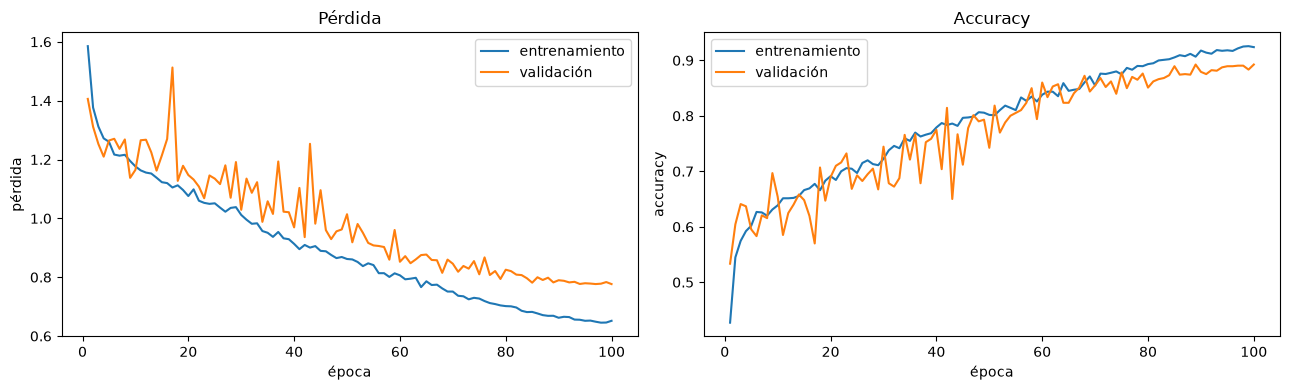

In [7]:
ep = [h['epoca'] for h in hist]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(ep, [h['train_loss'] for h in hist], label='entrenamiento'); a1.plot(ep, [h['val_loss'] for h in hist], label='validación')
a1.set_xlabel('época'); a1.set_ylabel('pérdida'); a1.set_title('Pérdida'); a1.legend()
a2.plot(ep, [h['train_acc'] for h in hist], label='entrenamiento'); a2.plot(ep, [h['val_acc'] for h in hist], label='validación')
a2.set_xlabel('época'); a2.set_ylabel('accuracy'); a2.set_title('Accuracy'); a2.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / 'curvas_cnn.png', dpi=120); plt.show()

## 5. Evaluación en el conjunto de prueba (imágenes nunca vistas)

Mejor época: 100


Accuracy test: 0.8868 | F1 macro: 0.8851

              precision    recall  f1-score   support

      Cartón      0.976     0.925     0.950       134
       Metal      0.770     0.897     0.829       116
    Orgánico      0.926     0.926     0.926       148
       Papel      0.941     0.911     0.926       158
    Plástico      0.752     0.838     0.793       130
      Vidrio      0.922     0.855     0.887       303

    accuracy                          0.887       989
   macro avg      0.881     0.892     0.885       989
weighted avg      0.893     0.887     0.888       989

Accuracy orgánico vs inorgánico: 0.9778


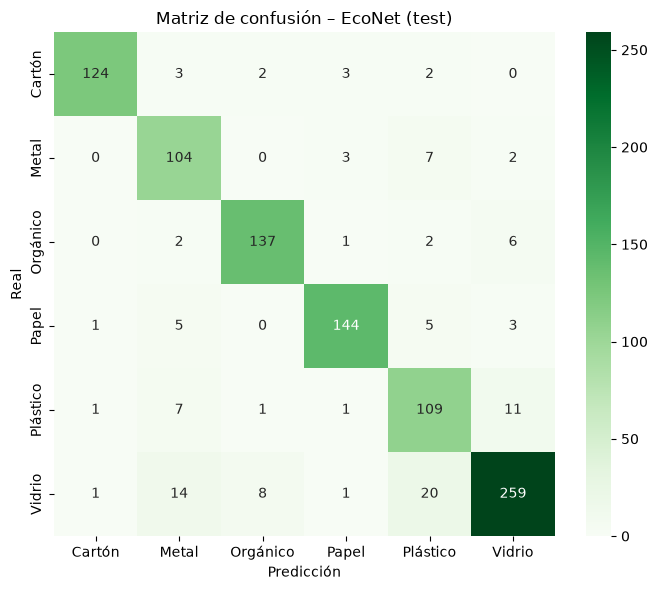

In [8]:
ckpt = torch.load(CNN_PESOS, map_location=device); modelo.load_state_dict(ckpt['modelo'])
print('Mejor época:', ckpt['epoca'])
tl, ta, tf1, ys, ps = evaluar(dl_test)
nombres = [INFO_CLASES[c]['nombre'] for c in CLASES]
print(f'Accuracy test: {ta:.4f} | F1 macro: {tf1:.4f}\n')
print(classification_report(ys, ps, target_names=nombres, digits=3))
tipo = lambda c: INFO_CLASES[CLASES[c]]['tipo']
acc_tipo = np.mean([tipo(a) == tipo(b) for a, b in zip(ys, ps)])
print(f'Accuracy orgánico vs inorgánico: {acc_tipo:.4f}')
cm = confusion_matrix(ys, ps)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=nombres, yticklabels=nombres)
plt.xlabel('Predicción'); plt.ylabel('Real'); plt.title('Matriz de confusión – EcoNet (test)')
plt.tight_layout(); plt.savefig(OUTPUTS / 'matriz_confusion_cnn.png', dpi=120); plt.show()

## 6. ¿Qué aprendió la CNN? Filtros y mapas de activación
Los 32 filtros de la primera capa se aprendieron desde cero. Abajo se ven los mapas de activación de un bloque intermedio: cada mapa muestra dónde detectó la red un patrón distinto.

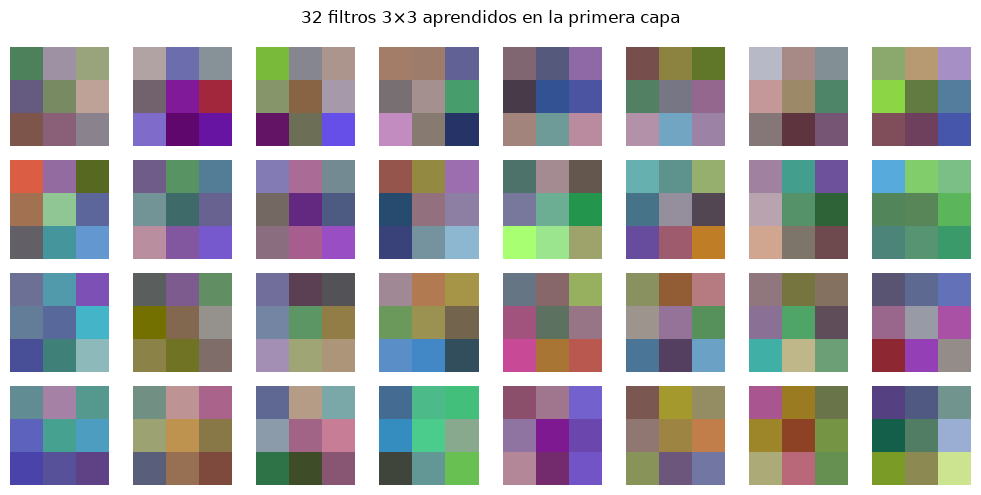

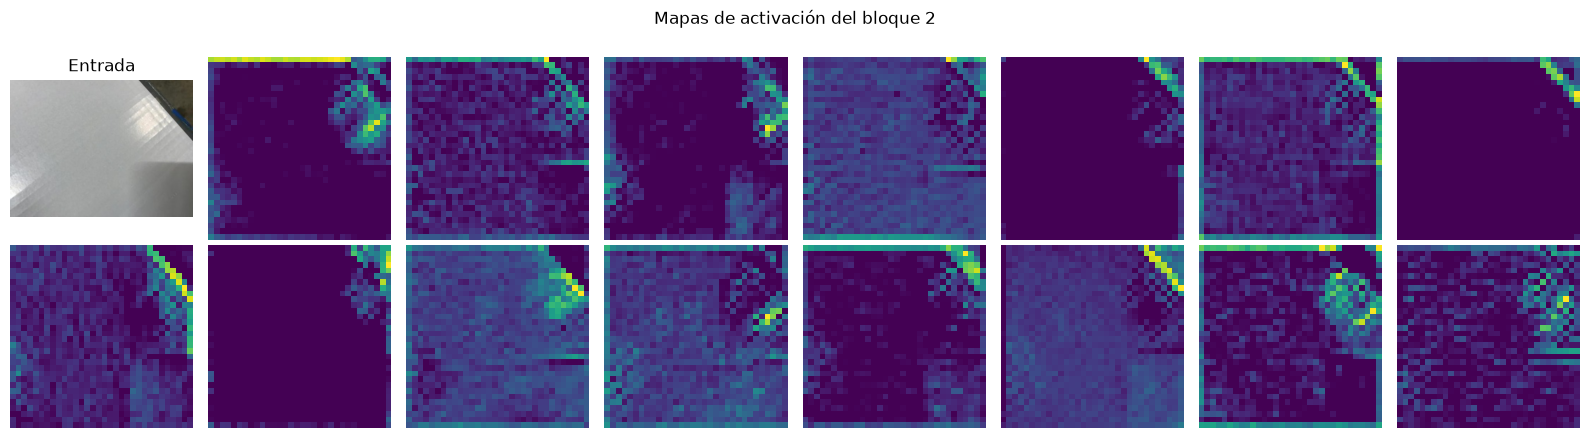

In [9]:
w = modelo.features[0][0].weight.detach().cpu()
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for ax, f in zip(axes.flat, w): ax.imshow(f.permute(1, 2, 0)); ax.axis('off')
plt.suptitle('32 filtros 3×3 aprendidos en la primera capa'); plt.tight_layout()
plt.savefig(OUTPUTS / 'filtros_cnn.png', dpi=120); plt.show()

img = ds['test'].imgs[10]
x = tf_evaluacion(img).unsqueeze(0).to(device)
with torch.no_grad():
    act = modelo.features[:2](x)[0].float().cpu()
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
axes[0, 0].imshow(img); axes[0, 0].set_title('Entrada'); axes[0, 0].axis('off')
for k, ax in enumerate(list(axes.flat)[1:]): ax.imshow(act[k], cmap='viridis'); ax.axis('off')
plt.suptitle('Mapas de activación del bloque 2'); plt.tight_layout()
plt.savefig(OUTPUTS / 'activaciones_cnn.png', dpi=120); plt.show()

## 7. Predicciones de ejemplo

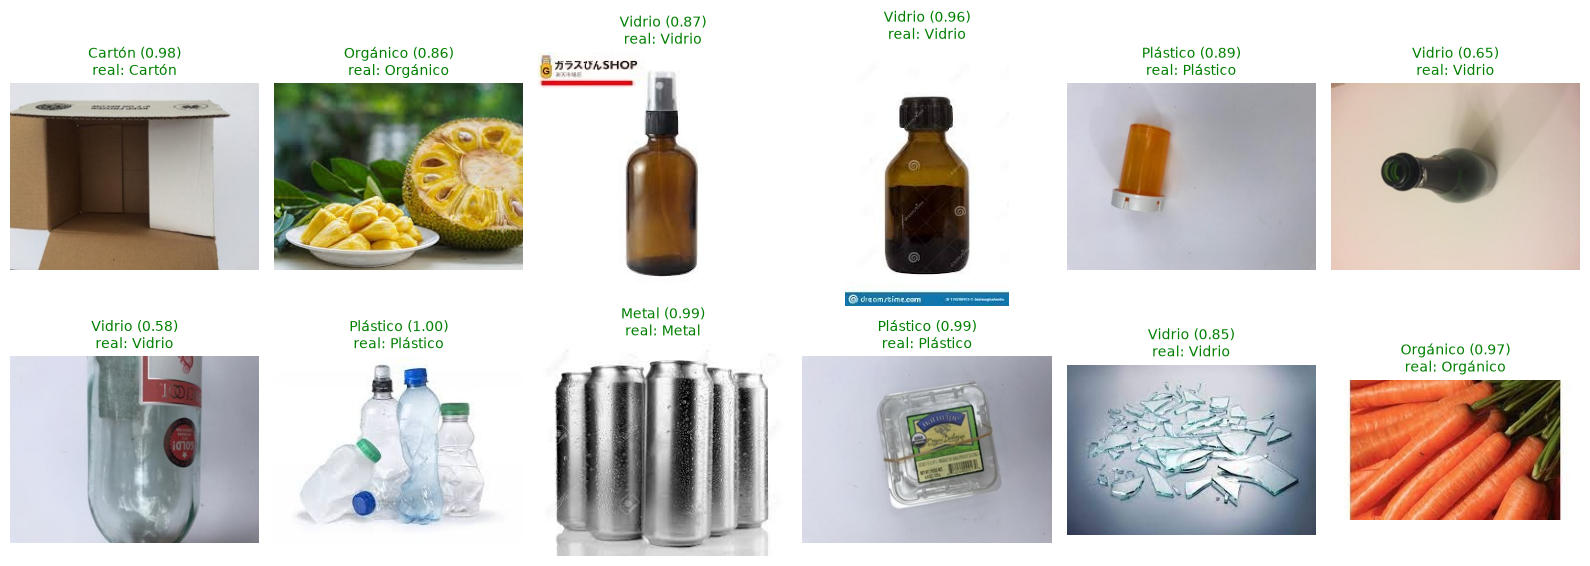

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
idx = np.random.default_rng(7).choice(len(ds['test']), 12, replace=False)
modelo.eval()
for ax, i in zip(axes.flat, idx):
    x, y = ds['test'][int(i)]
    with torch.no_grad(): p = modelo(x.unsqueeze(0).to(device)).softmax(-1)[0]
    c = int(p.argmax()); ok = c == y
    ax.imshow(ds['test'].imgs[int(i)]); ax.axis('off')
    ax.set_title(f"{INFO_CLASES[CLASES[c]]['nombre']} ({p[c]:.2f})\nreal: {INFO_CLASES[CLASES[y]]['nombre']}", color='green' if ok else 'red', fontsize=10)
plt.tight_layout(); plt.savefig(OUTPUTS / 'predicciones_cnn.png', dpi=120); plt.show()